# Clase 08 — Métodos de ensamble
## Predicción de quiebra de empresas

---

Somos el equipo de **riesgo crediticio** de un banco. Antes de prestarle a una empresa queremos saber: **¿va a quebrar?**

- **Pregunta:** dados 95 ratios financieros de una empresa, ¿cuál es la probabilidad de quiebra?
- **Datos:** 6.819 empresas con 95 ratios financieros (rentabilidad, endeudamiento, liquidez, flujo de caja). Dataset sintético, inspirado en datos reales de la bolsa de Taiwán. `Bankrupt? = 1` si la empresa quebró.
- **Modelos:** Random Forest y XGBoost, cada uno **sin y con GridSearch**. Cuatro modelos en total, comparados con las mismas métricas.

*Etapa de Modeling de CRISP-DM.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import joblib
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

sns.set_style("whitegrid")
SEED = 42

---
## 1. Carga y vistazo

In [2]:
df = pd.read_excel("quiebra_empresas.xlsx")
df.columns = df.columns.str.strip()   # el CSV trae espacios al inicio de cada nombre

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones: 6819 filas x 96 columnas


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,0,0.496383,0.548132,0.538622,0.624920,0.625177,0.998974,0.797168,0.809197,0.303571,...,0.805269,6.412603e+09,0.623913,0.624858,0.841437,0.286961,0.027357,0.565787,1,0.018009
1,0,0.487163,0.548110,0.536008,0.600191,0.599795,0.999334,0.797360,0.809447,0.303364,...,0.804797,5.209531e+06,0.623149,0.599815,0.840598,0.279919,0.026669,0.566264,1,0.030519
2,0,0.494234,0.551871,0.541851,0.604328,0.604654,0.998969,0.797730,0.809492,0.303777,...,0.805395,9.772863e+06,0.623503,0.603851,0.840990,0.280981,0.027024,0.565884,1,0.024593
3,0,0.540847,0.584857,0.582953,0.602788,0.602732,0.999086,0.797536,0.809841,0.303000,...,0.824009,4.924134e+06,0.623909,0.602459,0.842109,0.279869,0.026868,0.565320,1,0.030282
4,0,0.529072,0.603135,0.583833,0.602556,0.601916,0.999066,0.797339,0.809259,0.303431,...,0.836315,0.000000e+00,0.623638,0.602636,0.842909,0.276955,0.027070,0.565022,1,0.047200


---
## 2. EDA

Vista rápida, sin limpieza. Solo miramos tres cosas: el balance del target, si faltan datos y si hay variables constantes.

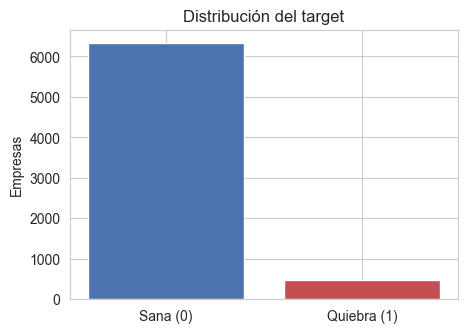

Quiebras: 478 (7.0%)  |  Sanas: 6341 (93.0%)


In [3]:
conteo = df["Bankrupt?"].value_counts()
pct = df["Bankrupt?"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Sana (0)", "Quiebra (1)"], conteo.values, color=["#4C72B0", "#C44E52"])
ax.set_ylabel("Empresas")
ax.set_title("Distribución del target")
plt.show()

print(f"Quiebras: {conteo[1]} ({pct[1]:.1f}%)  |  Sanas: {conteo[0]} ({pct[0]:.1f}%)")

**Observación:** solo ~7% de las empresas quiebra. Es una situación parecida a la del churn (Clase 07). Un modelo que diga "ninguna quiebra" acierta el 93% y es **inútil para un banco**. Por eso:

- **estratificamos** el split para que train y test tengan la misma proporción de quiebras;
- **compensamos el desbalance** en ambos modelos (`class_weight` en RF, `scale_pos_weight` en XGBoost);
- **accuracy no sirve**: miramos ROC-AUC, PR-AUC, recall y precision (Clase 06).

In [4]:
print("Valores nulos totales:", df.isna().sum().sum())

constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Columnas constantes:", constantes)

Valores nulos totales: 0
Columnas constantes: ['Net Income Flag']


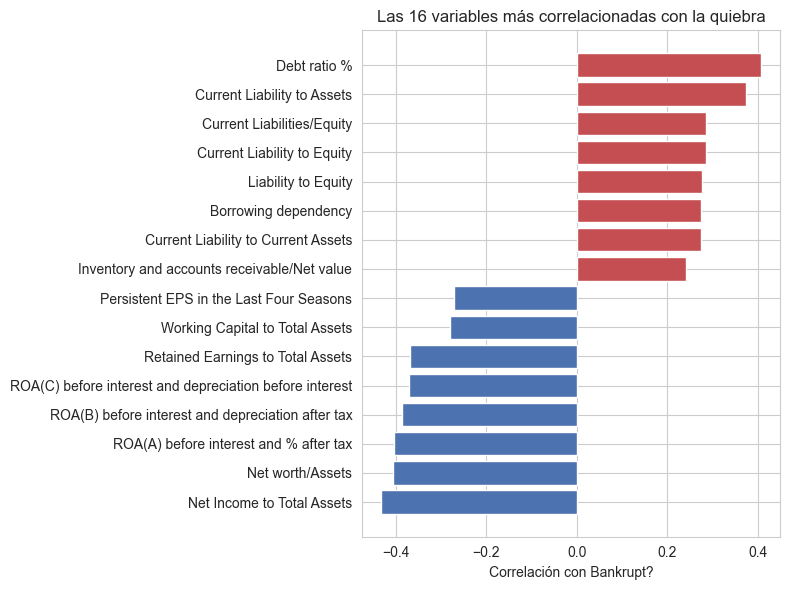

In [5]:
corr = df.corr()["Bankrupt?"].drop("Bankrupt?").dropna().sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in top.values])
ax.set_xlabel("Correlación con Bankrupt?")
ax.set_title("Las 16 variables más correlacionadas con la quiebra")
plt.tight_layout()
plt.show()

**Observación:** no hay nulos. Hay una columna constante que no aporta nada, pero a los árboles no les molesta: nunca la usan para partir. Rentabilidad (ROA, EPS, ingreso neto) correlaciona negativo con quiebra y endeudamiento positivo, tal como esperaría cualquier analista de crédito. Individualmente las correlaciones son bajas: la señal está en la **combinación** de ratios, que es justo lo que capturan los ensambles.

**Trampa conceptual:** hay ratios con valores extremos. Igual que en CART, **no los sacamos**: un ratio de deuda disparatado muchas veces *es* la señal de una empresa en problemas. Y tampoco escalamos: los árboles no lo necesitan (a diferencia de KNN, Clase 05).

---
## 3. Preparación

Un único split train/test estratificado. Todo lo que sigue (incluido el GridSearch) se ajusta **solo con train**; el test se toca una vez, al final.

In [6]:
X = df.drop(columns="Bankrupt?")
y = df["Bankrupt?"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

print(f"Train: {X_train.shape[0]} filas ({y_train.mean():.1%} quiebras)")
print(f"Test:  {X_test.shape[0]} filas ({y_test.mean():.1%} quiebras)")

peso_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Cada quiebra pesa ~{peso_pos:.0f} veces una empresa sana (scale_pos_weight)")

Train: 5114 filas (7.0% quiebras)
Test:  1705 filas (7.0% quiebras)
Cada quiebra pesa ~13 veces una empresa sana (scale_pos_weight)


**Observación:** `peso_pos` le dice a XGBoost cuántas veces más grave es equivocarse con una quiebra que con una empresa sana. Es el equivalente de `class_weight="balanced"` en Random Forest.

Definimos `evaluar` una sola vez para medir los cuatro modelos exactamente igual. Usamos umbral 0.5 para Recall/Precision/F1; ROC-AUC y PR-AUC no dependen del umbral.

In [7]:
resultados = []

def evaluar(nombre, modelo):
    proba = modelo.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    resultados.append({
        "modelo": nombre,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred),
    })
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{nombre}: detecta {tp} de {tp + fn} quiebras, con {fp} falsas alarmas")

---
## 4. Modelos

### 4.1 Random Forest sin GridSearch

Cientos de árboles entrenados sobre muestras distintas de filas y columnas; la predicción es el promedio. Cada árbol se equivoca distinto y al promediar el error baja (**bagging**). `class_weight="balanced"` evita que el bosque aprenda a decir "nadie quiebra".

In [8]:
rf_base = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
rf_base.fit(X_train, y_train)
evaluar("RF sin GridSearch", rf_base)

RF sin GridSearch: detecta 69 de 120 quiebras, con 22 falsas alarmas


### 4.2 Random Forest con GridSearch

Probamos combinaciones de profundidad, tamaño mínimo de hoja y columnas por split. Limitar la profundidad es la forma de frenar el sobreajuste. Elegimos con **PR-AUC** (`average_precision`) porque con 7% de positivos es mucho más exigente que accuracy. Validación cruzada estratificada de 5 folds **dentro de train**.

In [9]:
grid_rf = {
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.3],
}

gs_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    grid_rf,
    scoring="average_precision",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
)
gs_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", gs_rf.best_params_)
print(f"PR-AUC en CV: {gs_rf.best_score_:.3f}")
evaluar("RF con GridSearch", gs_rf.best_estimator_)

Mejores hiperparámetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5}
PR-AUC en CV: 0.759
RF con GridSearch: detecta 105 de 120 quiebras, con 57 falsas alarmas


### 4.3 XGBoost sin GridSearch

A diferencia de RF, acá los árboles se construyen **en secuencia**: cada uno corrige los errores del anterior (**boosting**). RF baja la varianza; XGBoost baja el sesgo. Por eso es más sensible a los hiperparámetros, sobre todo `learning_rate` y `max_depth`.

In [10]:
xgb_base = XGBClassifier(
    n_estimators=300,
    scale_pos_weight=peso_pos,
    eval_metric="aucpr",
    random_state=SEED,
    n_jobs=-1,
)
xgb_base.fit(X_train, y_train)
evaluar("XGBoost sin GridSearch", xgb_base)

XGBoost sin GridSearch: detecta 89 de 120 quiebras, con 36 falsas alarmas


### 4.4 XGBoost con GridSearch

Tocamos las perillas que más impactan: profundidad de cada árbol, velocidad de aprendizaje, cantidad de árboles y cuánta muestra de filas ve cada árbol (`subsample`).

In [11]:
grid_xgb = {
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [200, 400],
    "subsample": [0.8, 1.0],
}

gs_xgb = GridSearchCV(
    XGBClassifier(scale_pos_weight=peso_pos, eval_metric="aucpr", random_state=SEED, n_jobs=-1),
    grid_xgb,
    scoring="average_precision",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
)
gs_xgb.fit(X_train, y_train)

print("Mejores hiperparámetros:", gs_xgb.best_params_)
print(f"PR-AUC en CV: {gs_xgb.best_score_:.3f}")
evaluar("XGBoost con GridSearch", gs_xgb.best_estimator_)

Mejores hiperparámetros: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}
PR-AUC en CV: 0.757
XGBoost con GridSearch: detecta 114 de 120 quiebras, con 127 falsas alarmas


---
## 5. Comparación

In [12]:
tabla = pd.DataFrame(resultados).set_index("modelo").round(3)
tabla

,ROC-AUC,PR-AUC,Recall,Precision,F1
modelo,,,,,
RF sin GridSearch,0.977,0.772,0.575,0.758,0.654
RF con GridSearch,0.979,0.809,0.875,0.648,0.745
XGBoost sin GridSearch,0.975,0.786,0.742,0.712,0.727
XGBoost con GridSearch,0.978,0.823,0.950,0.473,0.632


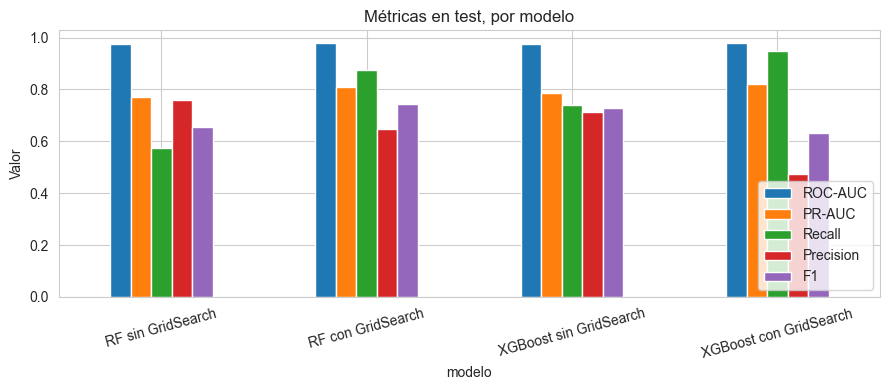

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
tabla.plot.bar(ax=ax, rot=15)
ax.set_ylabel("Valor")
ax.set_title("Métricas en test, por modelo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

---
## 6. Bajando el umbral para ganar recall

Hasta ahora usamos 0.5: el modelo marca "quiebra" solo si la probabilidad supera 50%. Para un banco, **no detectar una quiebra (falso negativo) sale mucho más caro que revisar de más una empresa sana (falsa alarma)**. Bajando el umbral detectamos más quiebras, a costa de más falsas alarmas. No reentrenamos nada: solo cambiamos dónde cortamos la probabilidad. Probamos los dos modelos con GridSearch.

In [14]:
filas = []
modelos_tuning = {"RF con GridSearch": gs_rf.best_estimator_, "XGBoost con GridSearch": gs_xgb.best_estimator_}

for nombre, modelo in modelos_tuning.items():
    proba = modelo.predict_proba(X_test)[:, 1]
    for umbral in [0.5, 0.45, 0.4, 0.35]:
        pred = (proba >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        filas.append({
            "modelo": nombre,
            "umbral": umbral,
            "Recall": recall_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred),
            "quiebras detectadas": tp,
            "falsas alarmas": fp,
        })

pd.DataFrame(filas).set_index(["modelo", "umbral"]).round(3)

Recall  Precision     F1  quiebras detectadas  \
modelo                 umbral                                                  
RF con GridSearch      0.50     0.875      0.648  0.745                  105   
                       0.45     0.892      0.622  0.733                  107   
                       0.40     0.908      0.583  0.710                  109   
                       0.35     0.925      0.547  0.687                  111   
XGBoost con GridSearch 0.50     0.950      0.473  0.632                  114   
                       0.45     0.958      0.449  0.612                  115   
                       0.40     0.958      0.412  0.576                  115   
                       0.35     0.958      0.383  0.548                  115   

                               falsas alarmas  
modelo                 umbral                  
RF con GridSearch      0.50                57  
                       0.45                65  
                       0.40                78  
                       0.35                92  
XGBoost con GridSearch 0.50               127  
                       0.45               141  
                       0.40               164  
                       0.35               185

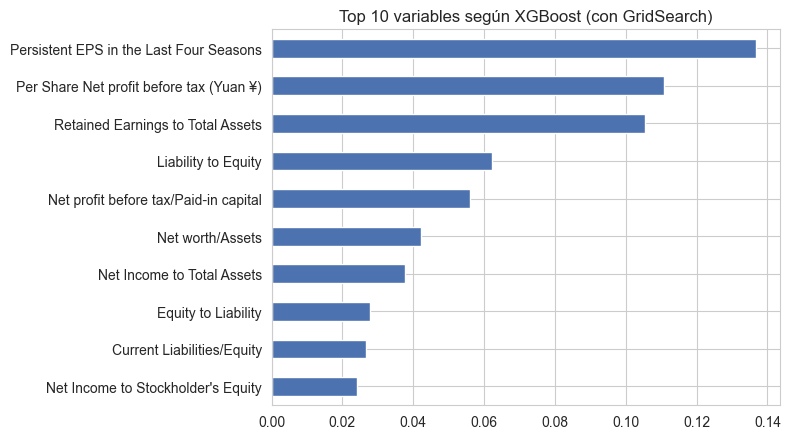

In [15]:
importancias = pd.Series(gs_xgb.best_estimator_.feature_importances_, index=X.columns).nlargest(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
importancias.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Top 10 variables según XGBoost (con GridSearch)")
plt.tight_layout()
plt.show()

---
## 7. Pipeline para producción

Elegimos **XGBoost con GridSearch**: es el de mejor PR-AUC y el que más quiebras detecta. Lo empaquetamos en un `Pipeline` para que el jefe (o cualquier compañero) pueda usarlo sin saber qué hay adentro:

1. **Imputación con la mediana:** hoy el dataset no tiene nulos, pero un dataset nuevo puede traerlos. Si pasa, el pipeline no se rompe.
2. **XGBoost** con los mejores hiperparámetros del GridSearch.

No escalamos: los árboles no lo necesitan (Clase 05, KNN, sí). Lo entrenamos **una vez** con train y lo guardamos en un archivo. Para usarlo con datos nuevos solo se carga y se predice; no se vuelve a entrenar (ver `practica08_pipeline.ipynb`).

In [16]:
pipeline = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("modelo", XGBClassifier(
        **gs_xgb.best_params_,
        scale_pos_weight=peso_pos,
        eval_metric="aucpr",
        random_state=SEED,
        n_jobs=-1,
    )),
])
pipeline.fit(X_train, y_train)

joblib.dump(pipeline, "pipeline_xgboost.joblib")
print("Pipeline guardado en pipeline_xgboost.joblib")

Pipeline guardado en pipeline_xgboost.joblib


### Tres umbrales, tres políticas de riesgo

El pipeline devuelve una **probabilidad**; el umbral lo define el negocio:

- **0.35 (agresivo):** el banco prefiere revisar de más antes que dejar pasar una quiebra.
- **0.50 (neutro):** el corte por defecto.
- **0.70 (conservador):** solo se marca cuando el modelo está muy seguro; pocas falsas alarmas, pero se escapan quiebras.

In [17]:
proba_test = pipeline.predict_proba(X_test)[:, 1]

filas = []
for umbral in [0.7, 0.5, 0.35]:
    pred = (proba_test >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({
        "umbral": umbral,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "quiebras detectadas": tp,
        "quiebras no detectadas": fn,
        "falsas alarmas": fp,
    })

print(f"ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}  |  PR-AUC: {average_precision_score(y_test, proba_test):.3f}  (no dependen del umbral)")
pd.DataFrame(filas).set_index("umbral").round(3)

ROC-AUC: 0.978  |  PR-AUC: 0.823  (no dependen del umbral)


,Recall,Precision,F1,quiebras detectadas,quiebras no detectadas,falsas alarmas
umbral,,,,,,
0.70,0.883,0.599,0.714,106,14,71
0.50,0.950,0.473,0.632,114,6,127
0.35,0.958,0.383,0.548,115,5,185
